# Optimal Transport Coupling for Flow Matching

In [19]:
import time

import torch 
from torch import nn, Tensor
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import numpy as np

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

### Load MNIST dataset

In [4]:


# Normalize pixel values from [0, 1] to [-1, 1] so the data matches a standard
# Gaussian source for flow matching.
transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = datasets.MNIST(root='../data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='../data', train=False, download=True, transform=transform)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f'Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}')
images, labels = next(iter(train_loader))
print(f'Batch images shape: {images.shape}, labels shape: {labels.shape}')

Train samples: 60000, Test samples: 10000
Batch images shape: torch.Size([128, 1, 28, 28]), labels shape: torch.Size([128])


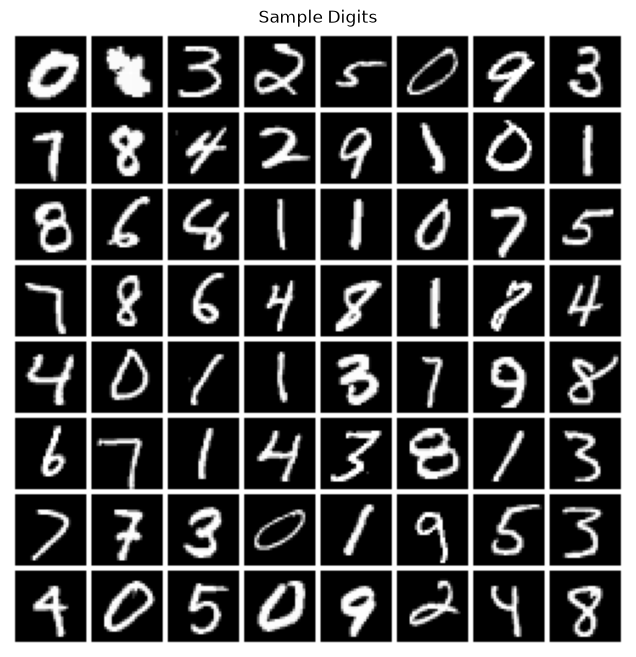

In [5]:
## Display some sample digits

def show_samples(images: Tensor, nrow: int=8, ax=None):
    # images = (images + 1) / 2  # denormalize
    images = images.clamp(0, 1)
    grid = make_grid(images[:nrow**2], nrow, padding=2, pad_value=1)
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))
    ax.set_aspect('equal')
    ax.set_title('Sample Digits')
    ax.imshow(grid.permute(1, 2, 0).cpu())
    ax.axis('off')
    return ax

show_samples(images);

In [9]:
class Flow(nn.Module):

    def __init__(self, dim: int=28*28, h: int=128):
        super().__init__()
        self.dim = dim
        self.h = h

        self.net = nn.Sequential(
            nn.Linear(dim+1, 2*h),
            nn.ReLU(),
            nn.Linear(2*h, h),
            nn.ReLU(),
            nn.Linear(h, 2*h),
            nn.ReLU(),
            nn.Linear(2*h, dim),
        )
    def forward(self, x, t):
        x_t = torch.cat([x, t], dim=1)
        return self.net(x_t)

    def step(self, x_t: Tensor, t_start: float, t_end: float):
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        dt = t_end - t_start
        return x_t + dt * self(x_t + self(x_t, t=t_start)*dt/2, t=(t_start + t_end)/2)



### Optimal transport coupling


In [10]:
from scipy.optimize import linear_sum_assignment
from scipy.spatial import distance

In [26]:
def train_flow(flow, train_loader, use_OT=True, n_epochs=50, lr=1e-3, sigma_noise=0.2, device=device):
    losses = []
    opt = torch.optim.Adam(flow.parameters(), lr=lr)
    t0 = time.time()
    for e in range(n_epochs):
        current_loss = 0.0
        for i, (x, _) in enumerate(train_loader):
            x_1 = x.view(-1, 784).to(device)

            t = torch.rand(x.shape[0], 1, device=x_1.device)
            x_0 = torch.randn_like(x_1)*sigma_noise + 0.5
            if use_OT:
                cost = distance.cdist(x_0.cpu().numpy(), x_1.cpu().numpy())
                row_ind, col_ind = linear_sum_assignment(cost)
                x_0, x_1 = x_0[row_ind], x_1[col_ind]

            dx_t = x_1 - x_0
            x_t = (1-t)*x_0 + t * x_1
            flow_pred = flow(x_t, t)

            loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
            loss.backward()
            opt.step()
            opt.zero_grad()

            # display progress with escape sequences to overwrite the previous line

            current_loss += loss.item()
        avg_loss = current_loss / len(train_loader)
        losses.append(avg_loss)
        print(f'\rEnd of epoch {e} of {n_epochs} at time {time.time() - t0:.2f}s, Loss: {avg_loss:.4f}', end='', flush=True)

    return losses

In [27]:
SIGMAS = [0.01, 0.1, 0.2, 0.5]
N_EPOCHS = 20

losses_OT = {}
flows_OT = {}
losses_nOT = {}
flows_nOT = {}
for sigma in SIGMAS:
    flows_OT[sigma] = Flow(h=256).to(device)
    losses_OT[sigma] = train_flow(flows_OT[sigma], train_loader, use_OT=True, n_epochs=N_EPOCHS, sigma_noise=sigma)

    flows_nOT[sigma] = Flow(h=256).to(device)
    losses_nOT[sigma] = train_flow(flows_nOT[sigma], train_loader, use_OT=False, n_epochs=N_EPOCHS, sigma_noise=sigma)


End of epoch 19 of 20 at time 43.90s, Loss: 207.09166

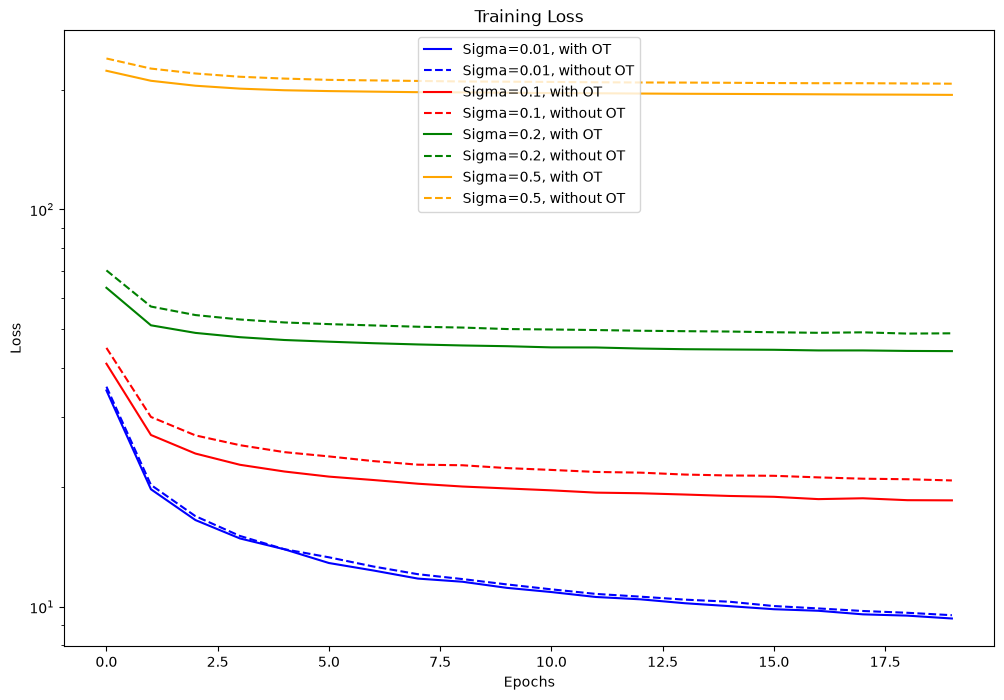

In [30]:
fig, ax = plt.subplots(figsize=(12, 8))
for sigma, c in zip(SIGMAS, ['blue', 'red', 'green', 'orange']):
    ax.plot(losses_OT[sigma], label=f'Sigma={sigma}, with OT', color=c)
    ax.plot(losses_nOT[sigma], label=f'Sigma={sigma}, without OT', color=c, linestyle='--')
ax.set_yscale('log')
ax.set_title('Training Loss')
ax.set_xlabel('Epochs')
ax.set_ylabel('Loss')
ax.legend()
plt.show()

In [12]:
N_EPOCHS = 100

flow = Flow(h=256).to(device)
opt = torch.optim.Adam(flow.parameters(), lr=1e-3)

for e in range(N_EPOCHS):
    for i, (x, _) in enumerate(train_loader):
        x_1 = x.view(-1, 784).to(device)

        t = torch.rand(x.shape[0], 1, device=x_1.device)
        x_0 = torch.randn_like(x_1)*0.2 + 0.5
        cost = distance.cdist(x_0.cpu().numpy(), x_1.cpu().numpy())
        row_ind, col_ind = linear_sum_assignment(cost)
        dx_t = x_1[col_ind] - x_0[row_ind]
        x_t = (1-t)*x_0[row_ind] + t * x_1[col_ind]
        flow_pred = flow(x_t, t)

        loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
        loss.backward()
        opt.step()
        opt.zero_grad()

        if i % 50 == 0:
            print(f'Epoch: {e}, Iter: {i}, Loss: {loss.item():.4f}')

Epoch: 0, Iter: 0, Loss: 206.8143
Epoch: 0, Iter: 50, Loss: 76.4659
Epoch: 0, Iter: 100, Loss: 70.1754
Epoch: 0, Iter: 150, Loss: 62.5675
Epoch: 0, Iter: 200, Loss: 61.4720
Epoch: 0, Iter: 250, Loss: 61.6926
Epoch: 0, Iter: 300, Loss: 56.6534
Epoch: 0, Iter: 350, Loss: 54.9414
Epoch: 0, Iter: 400, Loss: 53.9691
Epoch: 0, Iter: 450, Loss: 54.0584
Epoch: 1, Iter: 0, Loss: 53.2293
Epoch: 1, Iter: 50, Loss: 51.0182
Epoch: 1, Iter: 100, Loss: 52.0639
Epoch: 1, Iter: 150, Loss: 51.2561
Epoch: 1, Iter: 200, Loss: 51.8837
Epoch: 1, Iter: 250, Loss: 49.6777
Epoch: 1, Iter: 300, Loss: 49.8918
Epoch: 1, Iter: 350, Loss: 49.6872
Epoch: 1, Iter: 400, Loss: 49.6460
Epoch: 1, Iter: 450, Loss: 49.0076
Epoch: 2, Iter: 0, Loss: 50.6161
Epoch: 2, Iter: 50, Loss: 49.2680
Epoch: 2, Iter: 100, Loss: 49.0263
Epoch: 2, Iter: 150, Loss: 48.7620
Epoch: 2, Iter: 200, Loss: 48.9553
Epoch: 2, Iter: 250, Loss: 49.1361
Epoch: 2, Iter: 300, Loss: 47.2237
Epoch: 2, Iter: 350, Loss: 46.7901
Epoch: 2, Iter: 400, Loss: 4

KeyboardInterrupt: 

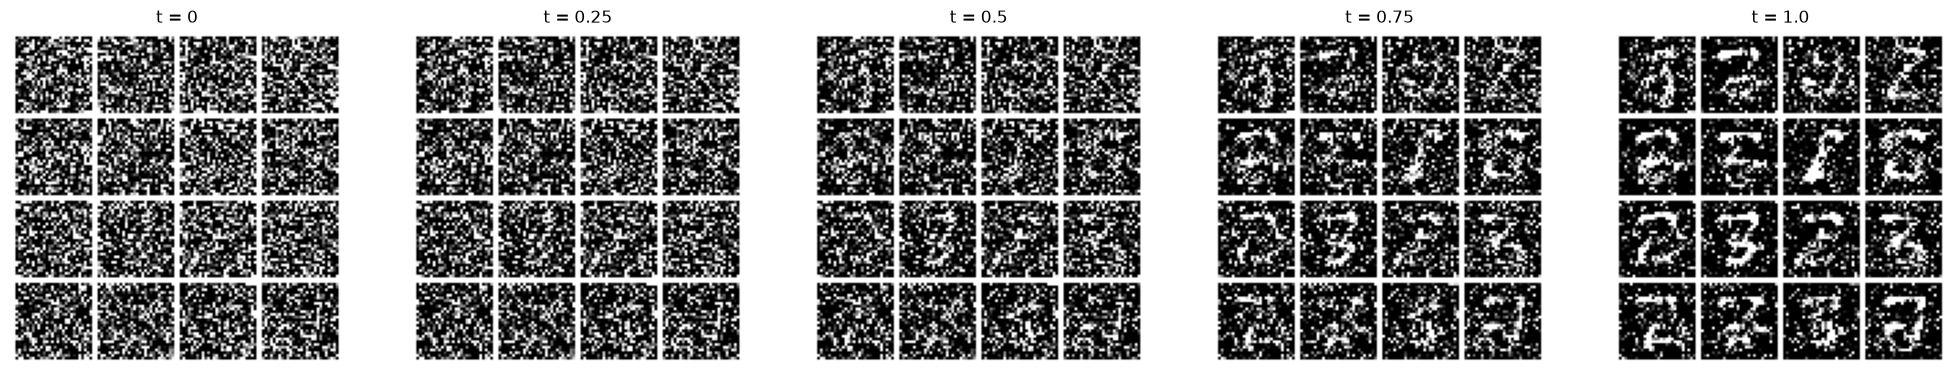

In [13]:
x = torch.randn(16, 784).to(device)
n_steps = 100
time_steps = torch.linspace(0, 1.0, n_steps + 1)

# Precompute the point cloud at every time step.
states = [x]
with torch.no_grad():
    for i in range(n_steps):
        x = flow.step(x_t=x, t_start=time_steps[i].to(device), t_end=time_steps[i + 1].to(device))
        states.append(x)
states = [s.detach() for s in states]

fig, ax = plt.subplots(1, 5, figsize=(25, 10))
ax = ax.reshape(-1)
ax[0] = show_samples(states[0].view(-1, 1, 28, 28), nrow=4, ax=ax[0])
ax[0].set_title('t = 0')
ax[1] = show_samples(states[25].view(-1, 1, 28, 28), nrow=4, ax=ax[1])
ax[1].set_title('t = 0.25')
ax[2] = show_samples(states[50].view(-1, 1, 28, 28), nrow=4, ax=ax[2])
ax[2].set_title('t = 0.5')
ax[3] = show_samples(states[75].view(-1, 1, 28, 28), nrow=4, ax=ax[3])
ax[3].set_title('t = 0.75')
ax[4] = show_samples(states[-1].view(-1, 1, 28, 28), nrow=4, ax=ax[4])
ax[4].set_title('t = 1.0')

plt.show()
